# Custom error-modelling in post-processing

Notebook: Vincent Verhoeven and  Hannah Weiser, 2026

HELIOS++ supports modelling of simple Gaussian noise on the distance measurements via the accuracy parameter in the scanner definition. This notebook demonstrates how more complex, custom error models can be implemented as a post-processing step. For this, we first simulate noise-free scans with HELIOS++, using a custom scanner definition, and then add distance-dependent Gaussian noise and further filter by a maximum incidence angle.

In [1]:
import numpy as np
import copy
import helios
from helios import units
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=456902374302593480495)
helios.add_asset_directory("../data")

Here, we define two functions for modelling the error as well as for filtering by incidence angle. The `pc` that they take as input are the measurement NumPy arrays as returned by the HELIOS++ Python API.

In [35]:
def add_scan_noise(pc, 
                   beam_divergence,
                   beam_exit_diameter,
                   sigma_range_0,
                   range_bias,
                   ):
    """
    This functions takes the helios output NumPy array (that includes x, y, z, distance and incidence_angle),
    adds the distance and beam-dependent Gaussian noise.
    """
    xyz = pc["position"]
    distance = pc["distance"]

    # range uncertainty
    beam_width = beam_exit_diameter + 2 * distance * np.tan(beam_divergence)
    sigma_radial = beam_width / 4  # as the beamwidth is defined to be 3 standard deviations, i.e., 2 in each direction
    sigma_range = sigma_range_0 + sigma_radial * np.tan(pc["incidence_angle"])

    # resulting range noise
    sn_noise = rng.standard_normal(xyz.shape[0])
    range_noise = range_bias + sigma_range * sn_noise
    distances_noisy = distance + range_noise

    # noisy point locations
    points_noisy = pc["beam_origin"] + pc["beam_direction"] * distances_noisy[0]
    pc_noisy = copy.deepcopy(pc)
    pc_noisy["position"] = points_noisy
    pc_noisy["distance"] = distances_noisy

    return pc_noisy


def filter_by_incidence_angle(pc, max_incidence_angle):
    """
    This functions takes the helios output NumPy array (that includes incidence_angle),
    and filters it by incidence angle
    """
    # remove points exceeding the maximum incidence angle
    filter_idx = pc["incidence_angle"] < max_incidence_angle
    pc_noisy_filtered = pc[filter_idx]

    return pc_noisy_filtered, filter_idx

[Maybe add a function here to write those to LAS/LAZ as well]

We load a custom scanner that has accuracy set to zero and will use a simple tripod to mount it to.

In [3]:
my_scanner_file = "test/test_scanners.xml"
scanner = helios.Scanner.from_xml(my_scanner_file, scanner_id="riegl_vz400_adj")
platform = helios.platform_from_name("tripod")

For demonstration, we are using the arbaro tree scene.

In [4]:
# load objs and create transformations
groundplane = helios.ScenePart.from_obj(
    "sceneparts/basic/groundplane/groundplane.obj",
).scale(
    100
)  # scale groundplane by 100
tree1 = helios.ScenePart.from_obj(
    "sceneparts/arbaro/black_tupelo_low.obj", up_axis="y"
)  # 3D models exported from Blender often have the Y-axis as "up-axis"
tree2 = helios.ScenePart.from_obj(
    "sceneparts/arbaro/sassafras_low.obj", up_axis="y"
)
# Trees should both be scaled down by half and translated
tree1 = tree1.scale(0.5).translate([0.0, 15.0, 0.0])
tree2 = tree2.scale(0.5).translate([-10.0, 15.0, 0.0])
# create scene
scene = helios.StaticScene(scene_parts=[groundplane, tree1, tree2])

In [5]:
scanner_settings = helios.ScannerSettings(
    pulse_frequency=100_000 * units.Hz,
    vertical_resolution=0.04 * units.deg,
    horizontal_resolution=0.04 * units.deg,
    min_vertical_angle=-40 * units.deg,
    max_vertical_angle=60 * units.deg,
)

survey = helios.Survey(
    scanner=scanner,
    platform=platform,
    scene=scene,
)
# first scan position
survey.add_leg(
    scanner_settings=scanner_settings,
    x=1.0,
    y=25.5,
    z=1.5,
    force_on_ground=True,  # this works because of the specification in the groundplane.mtl file
    rotation_start_angle=100 * units.deg,
    rotation_stop_angle=225 * units.deg,
)

points, trajectories = survey.run(
    verbosity=helios.LogVerbosity.VERBOSE, format=helios.OutputFormat.NPY
)

Legs:   0%|          | 0/1 [00:00<?, ?leg/s]

Current leg time: 0.00s [00:00, ?s/s]

In [ ]:
print(points["beam_origin"])
print(trajectories["position"])
print(points["beam_origin"] - trajectories["position"][0, :])
# seems like there is a shift between trajectory and beam_origin
# (the only shift that should be there is that introduced by scanner mount and
# scanner beam origin, which should be +1.5 m here)

[[ 1.        25.5       -5.2726975]
 [ 1.        25.5       -5.2726975]
 [ 1.        25.5       -5.2726975]
 ...
 [ 1.        25.5       -5.2726975]
 [ 1.        25.5       -5.2726975]
 [ 1.        25.5       -5.2726975]]
[[ 1.  25.5  0. ]
 [ 1.  25.5  0. ]
 [ 1.  25.5  0. ]
 ...
 [ 1.  25.5  0. ]
 [ 1.  25.5  0. ]
 [ 1.  25.5  0. ]]
[[ 0.         0.        -5.2726975]
 [ 0.         0.        -5.2726975]
 [ 0.         0.        -5.2726975]
 ...
 [ 0.         0.        -5.2726975]
 [ 0.         0.        -5.2726975]
 [ 0.         0.        -5.2726975]]


In [6]:
points_noisy = add_scan_noise(
    points,
    beam_divergence=0.0003,  # [rad]
    beam_exit_diameter=0.0,
    sigma_range_0=0.003,  # range uncertainty of the instrument [m]
    range_bias=0.0
)
points_noisy_filtered, _ = filter_by_incidence_angle(points_noisy,
                                                  max_incidence_angle=np.deg2rad(80)  # [rad]
                                                  )

Plot noise-free and noisy point clouds side-by-side.

In [7]:
print(points["position"])
print(points_noisy_filtered["position"])

[[-1.29667761e+00  2.50936286e+01  4.66436401e-04]
 [-1.00018517e+00  2.51461127e+01  4.06216023e-04]
 [-1.30004862e+00  2.50930319e+01  4.67121085e-04]
 ...
 [ 2.11585009e+01  5.32760403e+00  5.70361656e-03]
 [ 2.13982298e+01  5.08771467e+00  5.77144482e-03]
 [ 2.16965979e+01  4.78914586e+00  1.50046651e-03]]
[[-1.29575513 25.09379187 -6.97154843]
 [-1.17857271 25.11455108 -7.12387043]
 [-1.2969224  25.09358506 -6.96992038]
 ...
 [ 2.9165212  23.58197299 -6.25743606]
 [ 3.00783493 23.49070347 -5.77560651]
 [ 3.00808285 23.49045584 -5.77362332]]


(4588086,)
(3806040,)


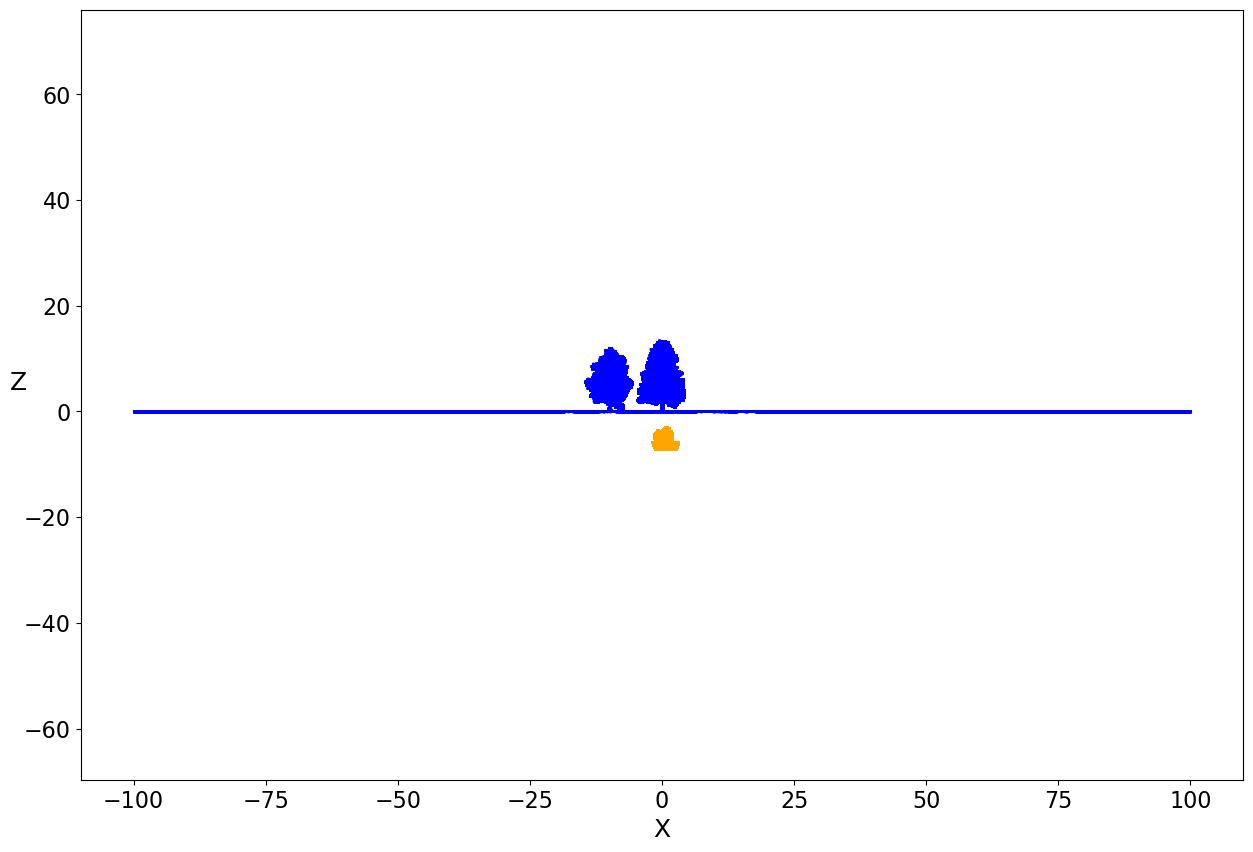

In [ ]:
def clip_by_bb(pts, xmin, xmax, ymin, ymax, zmin, zmax):
    pos = pts["position"]
    clip_index = (
        (pos[:, 0] > xmin)
        & (pos[:, 0] < xmax)
        & (pos[:, 1] > ymin)
        & (pos[:, 1] < ymax)
        & (pos[:, 2] > zmin)
        & (pos[:, 2] < zmax)
    )
    return clip_index

fig, ax = plt.subplots(figsize=(15, 10))
colors = ["blue", "orange"]

for i, pc in enumerate([points, points_noisy_filtered]):
    print(pc.shape)
    # pc_sub  = pc[clip_by_bb(pc, -10, -9, 10, 15, 0, 2)]
    # pos = pc_sub["position"]
    pos = pc["position"]
    ax.scatter(pos[:, 0], pos[:, 2], s=1, alpha=0.5, c=colors[i])
    plt.axis("equal")
    ax.tick_params(labelsize=16)
    plt.xlabel("X", fontsize=18)
    plt.ylabel("Z", fontsize=18, rotation=0)
plt.show()

# noisy point cloud shifted due to internal scene shift still applied to beam_origin???